# 2D+t Root System Architecture

# Load the code to read and transform RSA to networkx trees

In [51]:
from pathlib import Path
from pprint import pprint
from openalea.widgets.mtg import plot as plot_mtg
%run read.py

## Load the data

Each file represent the 2D+t root topology of 5 arabidopsis plants

In [52]:
from pathlib import Path
from pprint import pprint

data = Path('data')/'UC1_HIRROS_arabidopsis'
rsa_files = list(data.glob('*.rsml'))
pprint(rsa_files)

[PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN016.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN017.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN021.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN026.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN007.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN028.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN033.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN005.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN013.rsml'),
 PosixPath('data/UC1_HIRROS_arabidopsis/UC1_230629PN015.rsml')]


In [53]:
fn = rsa_files[0]
g = convert_fine_mtg(fn)
# Split the forest into 5 independent graphs
g1, g2, g3, g4, g5 = gs =  split(g)


In [54]:
# Plot one RSA
times_ = times(g1)
plot_mtg(g1)

In [55]:
# Convert all the graphs into NetworkX DAG
dgs = [convert_nx(g) for g in gs]
dg1, dg2, dg3, dg4, dg5 = dgs

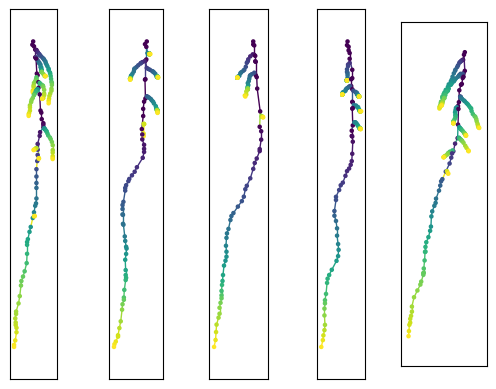

In [56]:
fig, axes = plt.subplots(1,5)
for i in range(5):
    plot_mpl(dgs[i], ax=axes[i])

------------------

# New dataset from old data format (the actual in production)

In [75]:
from pathlib import Path
from pprint import pprint

data = Path('data')/'RSPM_Ariadne_2025/H10/Hetero_G'
rsa_files = list(data.glob('*.rsml'))
pprint(rsa_files)

[PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p47.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p51.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p71.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p27.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p07.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p11.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p63.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p59.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p55.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p15.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p39.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p19.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p23.rsml'),
 PosixPath('data/RSPM_Ariadne_2025/H10/Hetero_G/p35.rsml')]


In [76]:

%run read.py
fn = rsa_files[0]
g = convert_fine_mtg(fn)
# Split the forest into n independent graphs
gs =  split(g)

In [77]:
# Debug
g= rsml.rsml2mtg(fn)
plants = g.vertices(scale=1)
plants
print(fn)
g.property('diameter')

data/RSPM_Ariadne_2025/H10/Hetero_G/p47.rsml


{}

In [78]:
# Plot one RSA
times_ = times(g1)
plot_mtg(g1)

In [79]:
# Convert all the graphs into NetworkX DAG
dgs = [convert_nx(g) for g in gs]

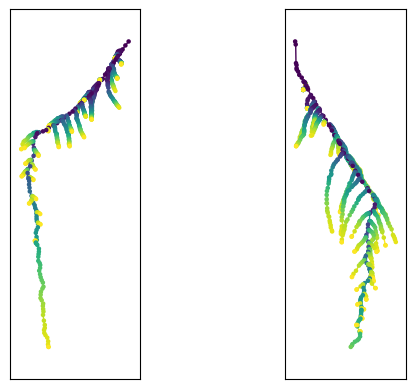

In [80]:
n = len(dgs)
fig, axes = plt.subplots(1,n)
for i in range(n):
    plot_mpl(dgs[i], ax=axes[i])

In [81]:
all_dgs = []
for fn in rsa_files:
    g = convert_fine_mtg(fn)
    gs =  split(g)
    dgs = [convert_nx(g) for g in gs]
    all_dgs.append(dgs)

Distance to the closest point  20.180436070610565
Distance to the closest point  20.112185361118765
Distance to the closest point  20.615528128088304
Distance to the closest point  42.42640687119285
Distance to the closest point  21.592822881689184
Distance to the closest point  26.953663943887108
Distance to the closest point  22.89650628371062
Distance to the closest point  28.653097563788805
Distance to the closest point  31.240998703626616
Distance to the closest point  21.592822881689184
Distance to the closest point  22.67156809750927
Distance to the closest point  31.240998703626616
Distance to the closest point  22.726636354727024
Distance to the closest point  32.64965543462902
Distance to the closest point  22.41093483101497
Distance to the closest point  28.42534080710379
Distance to the closest point  30.479501308256342
Distance to the closest point  38.28837943815329
Distance to the closest point  21.93171219946131


In [82]:
m = len(all_dgs)
n = max([len(dg) for dg in all_dgs])

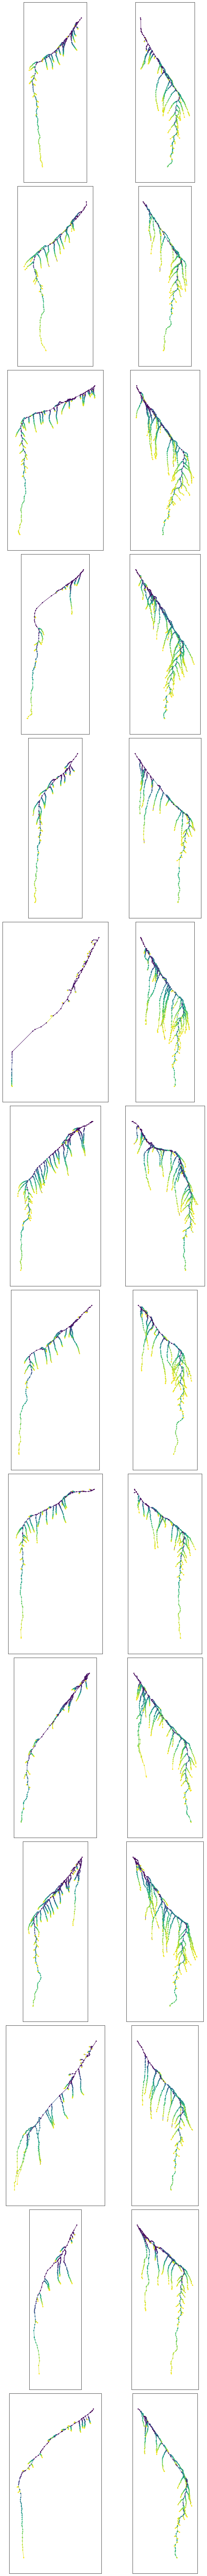

In [83]:

fig, axes = plt.subplots(m,n, figsize=(10,100))
for i in range(m):
    for j in range(n):
        plot_mpl(all_dgs[i][j], ax=axes[i][j])

plt.tight_layout()